find out using exploratory data analysis: 
- How much data is missing, and whether certain stations are more affected
- How water levels vary between stations and over time
- Which characteristics of the stations would be useful for clustering.
- Whether missing data could bias your clustering and flood prediction models.

Station locations - Plot all stations on a map to see their geographical distribution
Missing data per station - Identify which stations have the most missing readings
Water-level distributions - Use histograms or boxplots to compare stations
Water levels over time - Plot a few stations to investigate trends and seasonal patterns



Minimum vs average vs maximum levels

MLP week on clustering: week 3
Once we have chosen or designed a measure of dissimilarity between observations in our
dataset, our objective is to try and assign each data point to one of K distinct clusters
(with K < N )
Our goal is to find the clustering C which minimises the total within cluster variation,
that is, we seek a method to partition the observations into K groups such that the loss
in (3) is minimised
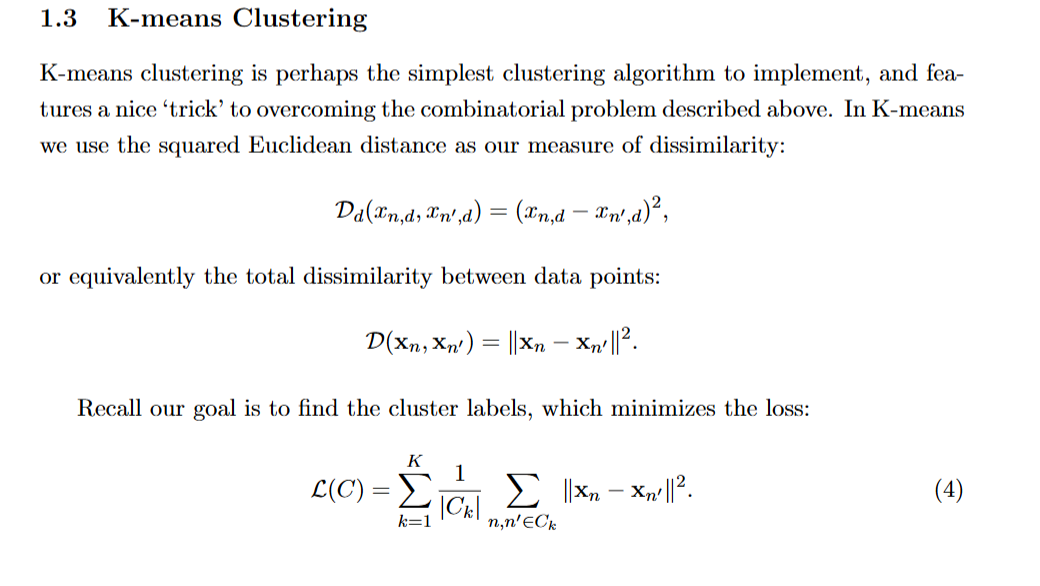
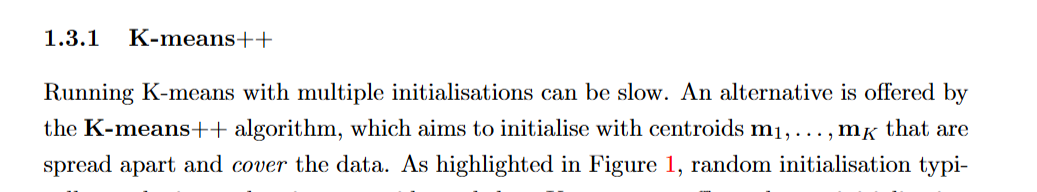
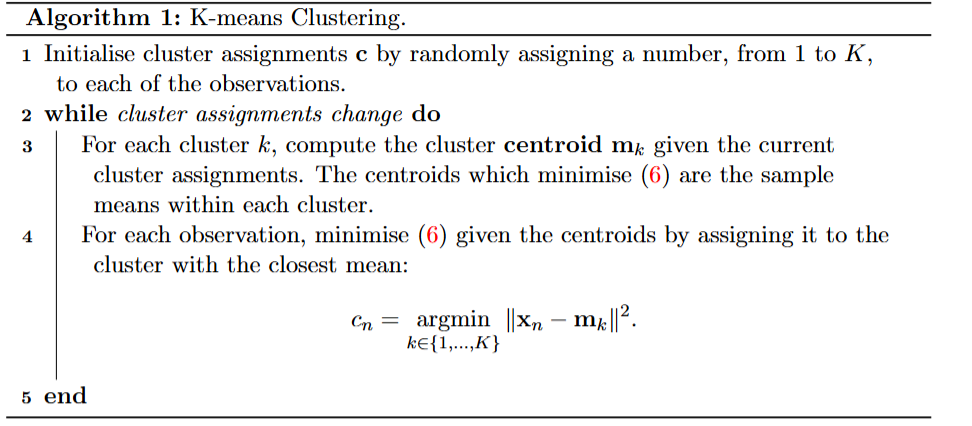

In [2]:
# Data libraries

import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn modules
import sklearn

df_avg = pd.read_csv("avg_river_levels.csv")
df_min = pd.read_csv("min_river_levels.csv")
df_max = pd.read_csv("max_river_levels.csv")
df_locs = pd.read_csv("monitoring_locations.csv")
df_avg.head()


,County,Station_Name,Observation_ID,05/10/2014,06/10/2014,07/10/2014,08/10/2014,09/10/2014,10/10/2014,13/10/2014,...,29/09/2026,30/09/2026,01/10/2026,02/10/2026,03/10/2026,04/10/2026,05/10/2026,06/10/2026,07/10/2026,08/10/2026
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.133,0.152,0.169,0.143,0.136,0.130,0.126,0.120,0.120,0.120
1,aberdeenshire,"Dee (Grampian), Mar Lodge",aberdeenshire__dee-grampian-mar-lodge__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.721,0.971,0.849,0.799,0.861,0.752,0.727,0.695,0.677,0.669
2,aberdeenshire,"Dee (Grampian), Park",aberdeenshire__dee-grampian-park__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.934,0.973,1.264,0.990,1.054,0.988,0.918,0.887,0.854,0.836
3,aberdeenshire,"Dee (Grampian), Polhollick",aberdeenshire__dee-grampian-polhollick__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.483,0.704,0.683,0.530,0.676,0.530,0.496,0.460,0.438,0.427
4,aberdeenshire,"Dee (Grampian), Woodend",aberdeenshire__dee-grampian-woodend__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.578,0.700,0.861,0.645,0.739,0.642,0.583,0.547,0.514,0.495


avg is missing 525,877 values (30.61%)
min is missing 525,877 values (30.61%)
max is missing 525,877 values (30.61%)


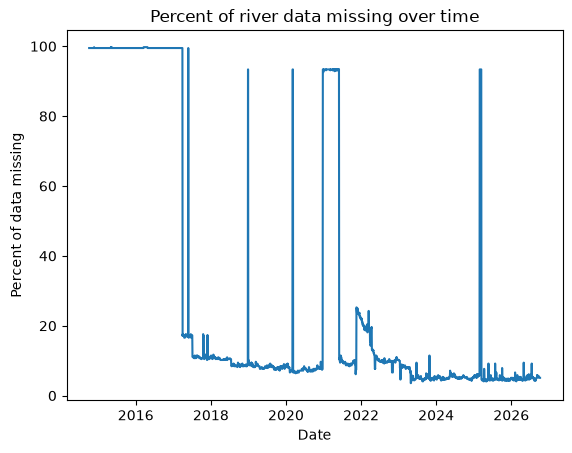

In [3]:
#missing value investigations

for name, df in [("avg", df_avg), ("min", df_min), ("max", df_max)]:
    missing = df.isna().sum().sum()
    total = df.size
    print(f"{name} is missing {missing:,} values ({missing / total * 100:.2f}%)")


#plotting the missing values againt date
missing = df_avg.iloc[:, 3:].isna().mean(axis=0) * 100

plt.plot(pd.to_datetime(missing.index, dayfirst=True), missing)
plt.xlabel("Date")
plt.ylabel("Percent of data missing")
plt.title("Percent of river data missing over time")
plt.show()





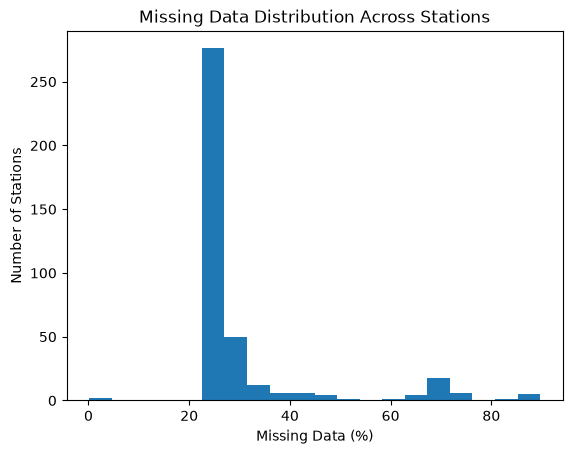

In [4]:
#histograms of the missing values 
missing_station = df_avg.iloc[:, 3:].isna().mean(axis=1) * 100

plt.hist(missing_station, bins=20)
plt.xlabel("Missing Data (%)")
plt.ylabel("Number of Stations")
plt.title("Missing Data Distribution Across Stations")
plt.show()

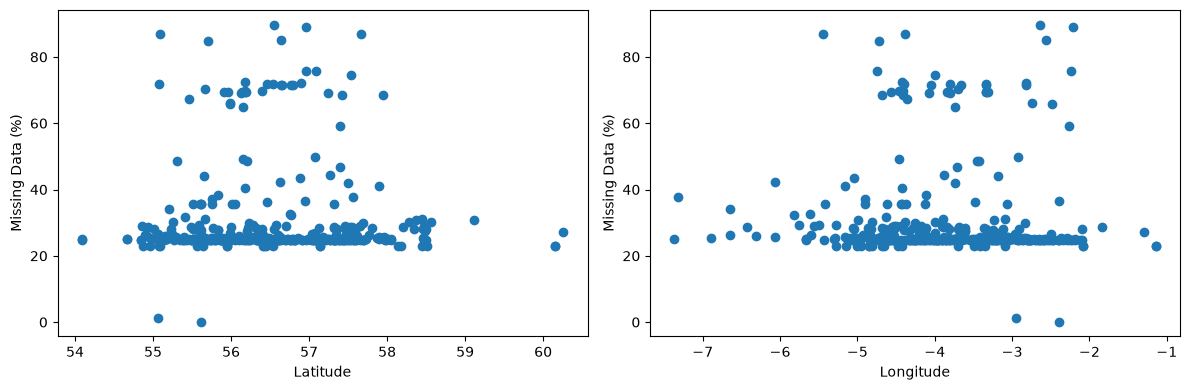

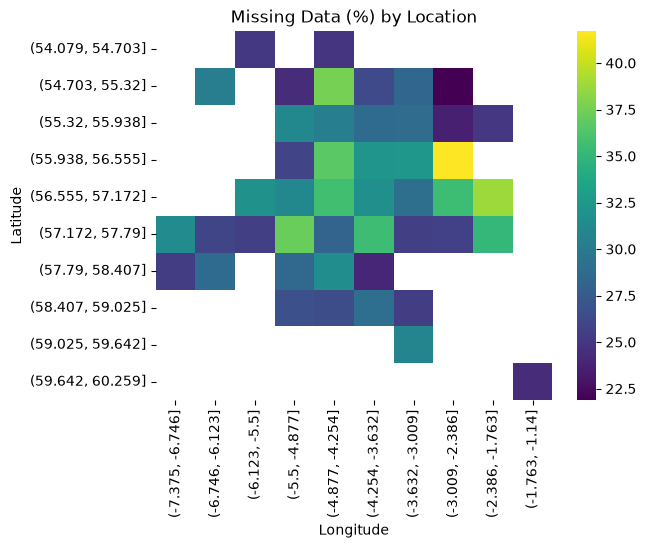

In [ ]:
missing_station = df_avg.iloc[:, 3:].isna().mean(axis=1) * 100

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

axs[0].scatter(df_locs["Latitude"], missing_station)
axs[0].set_xlabel("Latitude")
axs[0].set_ylabel("Missing Data (%)")

axs[1].scatter(df_locs["Longitude"], missing_station)
axs[1].set_xlabel("Longitude")
axs[1].set_ylabel("Missing Data (%)")

plt.tight_layout()
plt.show()

#the above does not show as well where the missing data is concentrated 


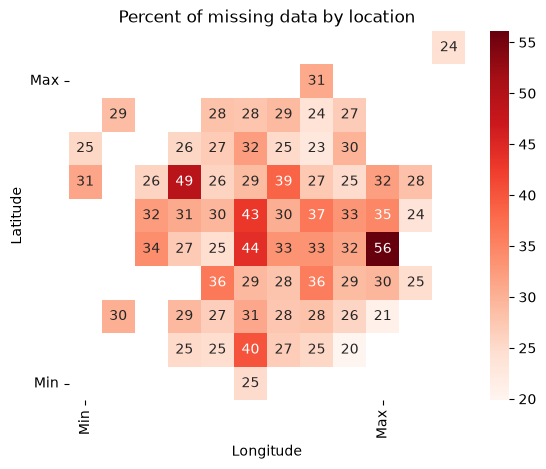

In [41]:
#https://seaborn.pydata.org/generated/seaborn.heatmap.html as a reference and the week 1 workshop
#https://pandas.pydata.org/docs/reference/api/pandas.cut.html

#colour map
missing_station = df_avg.iloc[:, 3:].isna().mean(axis=1) * 100

df_map = df_locs.copy()
df_map["Missing"] = missing_station

#sorting into categorical variables
df_map["Latitude"] = pd.cut(df_map["Latitude"], bins=12, ordered = True)
df_map["Longitude"] = pd.cut(df_map["Longitude"], bins=12)

heatmap_data = df_map.pivot_table(values="Missing",index="Latitude",columns="Longitude")
sns.heatmap(heatmap_data, annot=True, cmap = 'Reds')
plt.title("Percent of missing data by location")
plt.xticks([0.5, 9.5], ["Min", "Max"])
plt.yticks([0.5, 9.5], ["Min", "Max"])
plt.gca().invert_yaxis()
plt.show()

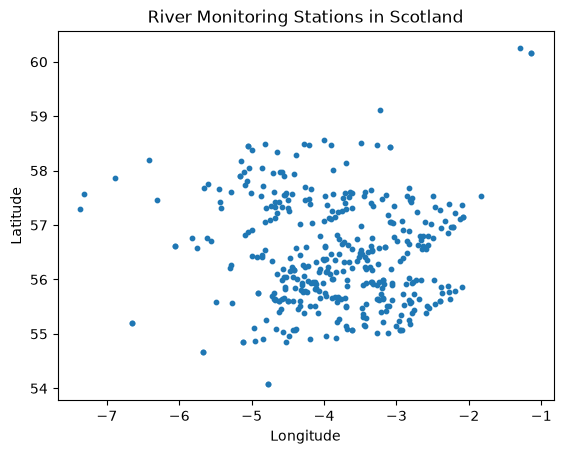

In [22]:
#map of the stations for clustering 

plt.scatter(df_locs["Longitude"], df_locs["Latitude"], s=10)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("River Monitoring Stations in Scotland")
plt.show()